# Teste — bbox calibrado da Opção 2 (perda zero garantida) na imagem IMG_ID=302

Modelado na célula "bbox aproximado + Rv" de
[check_aorta_anchor.ipynb](../src/eda/check_aorta_anchor.ipynb) (a que desenha o retângulo do
bbox sobre fatias com o label sobreposto e calcula `Rv`) — mas usando o bbox **calibrado da Opção
2**, não o bbox "aproximado" daquela célula (que era só o bounding box do próprio label da
imagem, ilustrativo). Aqui o bbox vem da calibração real: critério C (`aorta_voxels`,
`exclusion_pct=5%`, sobre os 994 casos inteiros) + `offset_percentile=98` sobre a curva de N×Rv
com perda real zero garantida — ver [docs/STATUS.md](../docs/STATUS.md) e
[docs/step6v2_aorta_anchor.md](../docs/step6v2_aorta_anchor.md), seção "Otimização N × Rv com
perda real zero garantida".

**IMG_ID=302** foi conferido prévia e independentemente (fora deste notebook): sobrevive ao
critério C a 5% e tem perda real (voxel a voxel) = 0% neste bbox — "sem perda de informação das
artérias" (a garantia central da Opção 2) se confirma para este caso específico, não é assumida.

Sem reprocessar segmentação da aorta: a âncora já está persistida em `all_cases.csv` (etapa 6 v2,
lote já executado) — só `load_and_preprocess_image` (etapas 1-4, downscale+threshold+LCC) é
rodado aqui, para ter a imagem de fundo e o label em resolução reduzida para a visualização.

In [1]:
# ruff: noqa: E402
import sys
from pathlib import Path

NOTEBOOK_CWD = Path.cwd().resolve()
for candidate in (
    NOTEBOOK_CWD,
    NOTEBOOK_CWD.parent,
    NOTEBOOK_CWD.parent.parent,
):
    src_dir = candidate / "src"
    if src_dir.exists():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break

from utils.project.notebook_env import configure_notebook_environment  # noqa: E402

REPO_ROOT = configure_notebook_environment()
print(f"REPO_ROOT = {REPO_ROOT}")


REPO_ROOT = G:\DAC\heart-bounding-box


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from utils.project.config import load_config_json
from utils.segmentation.aorta_anchor import select_cases_by_aorta_volume_percentile
from utils.segmentation.bbox_crop import compute_percentile_offsets
from utils.segmentation.pipeline_preprocessing import load_and_preprocess_image
from utils.utils.nifti_io import load_raw_img_and_label

IMG_ID = 302
DOWNSCALE_FACTORS = (2, 2, 1)
CONFIG_PATH = REPO_ROOT / "config" / "pipeline_config.json"
DATASET_ROOT = REPO_ROOT / "dataset"
AORTA_ANCHOR_DIR = REPO_ROOT / "output" / "bounding_box" / "aorta_anchor"

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset não encontrado em {DATASET_ROOT}. Confirme o symlink/junction 'dataset' "
        "na raiz do repositório (ver .gitignore)."
    )


## 1. Calibração da Opção 2 (critério C 5% + offset_percentile=98, população inteira)

Reaproveita `select_cases_by_aorta_volume_percentile` (critério C) e `compute_percentile_offsets`
(extraída de `evaluate_percentile_bbox_tradeoff`, ver `bbox_crop.py`) — funções já commitadas e
testadas, sem reimplementar a lógica de calibração aqui.

In [3]:
all_cases = pd.read_csv(AORTA_ANCHOR_DIR / "all_cases.csv")

excluded_df, filtered_df = select_cases_by_aorta_volume_percentile(all_cases, exclusion_pct=5.0)
print(f"Critério C a 5% (população inteira, 994 casos): {len(filtered_df)} incluídos, "
      f"{len(excluded_df)} excluídos")

offset_min, offset_max = compute_percentile_offsets(filtered_df, offset_percentile=98.0)
print(f"\noffset_min (resolução reduzida) = {offset_min}")
print(f"offset_max (resolução reduzida) = {offset_max}")

bbox_extent_reduced = {axis: offset_max[axis] - offset_min[axis] for axis in ("y", "x", "z")}
bbox_extent_full = {
    axis: bbox_extent_reduced[axis] * factor
    for axis, factor in zip(("y", "x", "z"), DOWNSCALE_FACTORS)
}
print(f"\nbbox_extent (resolução reduzida) = {bbox_extent_reduced}")
print(f"bbox_extent (resolução integral)  = {bbox_extent_full}")
print("Documentado em docs/step6v2_aorta_anchor.md ('Otimização N × Rv...', offset_percentile=98%): "
      "436,2 × 379,0 × 257,4 -- confira que bate com bbox_extent_full acima.")

IMG_ID_INCLUDED = IMG_ID in set(filtered_df["img_id"])
print(f"\nIMG_ID={IMG_ID} sobrevive ao critério C a 5%? {IMG_ID_INCLUDED}")
if not IMG_ID_INCLUDED:
    raise RuntimeError(
        f"IMG_ID={IMG_ID} foi excluído pelo critério C -- escolha outro caso "
        "(não deveria acontecer, já checado fora deste notebook antes de escrevê-lo)."
    )


Critério C a 5% (população inteira, 994 casos): 944 incluídos, 50 excluídos

offset_min (resolução reduzida) = {'y': -74.60926130924716, 'x': -85.54292266809541, 'z': -199.30336796153983}
offset_max (resolução reduzida) = {'y': 143.51170919000785, 'x': 103.96445783473408, 'z': 58.08713773573978}

bbox_extent (resolução reduzida) = {'y': 218.120970499255, 'x': 189.5073805028295, 'z': 257.3905056972796}
bbox_extent (resolução integral)  = {'y': 436.24194099851, 'x': 379.014761005659, 'z': 257.3905056972796}
Documentado em docs/step6v2_aorta_anchor.md ('Otimização N × Rv...', offset_percentile=98%): 436,2 × 379,0 × 257,4 -- confira que bate com bbox_extent_full acima.

IMG_ID=302 sobrevive ao critério C a 5%? True


## 2. Pré-processamento (etapas 1-4) — só para a visualização

`load_and_preprocess_image` roda downscale → threshold HU → LCC por fatia (etapas 1-4).
Não redetecta a aorta (Hough+Level Set) — a âncora já está em `all_cases.csv`, calculada no lote
já executado.

In [4]:
CONFIG = load_config_json(str(CONFIG_PATH), {})
row = filtered_df.loc[filtered_df["img_id"] == IMG_ID].iloc[0]
block = row["block"]
base_path = DATASET_ROOT / block

image_data = load_and_preprocess_image(IMG_ID, str(base_path), CONFIG)
lcc_image = image_data["lcc_image"]
label = image_data["label"]
scaled_spacing = image_data["scaled_spacing"]
label_artery = label == 1

anchor_y, anchor_x, anchor_z = row["anchor_y"], row["anchor_x"], row["anchor_z"]

print(f"lcc_image: shape={lcc_image.shape}")
print(f"Âncora (y, x, z) = ({anchor_y:.2f}, {anchor_x:.2f}, {anchor_z:.2f})")
print(f"Voxels de artéria (label, resolução reduzida): {int(label_artery.sum())}")


lcc_image: shape=(256, 256, 229)
Âncora (y, x, z) = (74.73, 136.99, 174.44)
Voxels de artéria (label, resolução reduzida): 23105


## 3. Bbox calibrado (Opção 2) aplicado a esta imagem

Ao contrário da célula equivalente em `check_aorta_anchor.ipynb` (que usava o bbox aproximado —
o bounding box do próprio label desta imagem, sempre 100% coberto por construção), aqui o bbox
vem da **calibração real** (célula 1 acima) — cobertura não é garantida por construção para
qualquer caso individual, é verificada explicitamente na célula seguinte.

bbox calibrado (min) y,x,z = (np.float64(0.1), np.float64(51.4), np.float64(-24.9))
bbox calibrado (max) y,x,z = (np.float64(218.2), np.float64(241.0), np.float64(232.5))
bbox extent (y, x, z)      = (np.float64(218.1), np.float64(189.5), np.float64(257.4)) voxels (resolução reduzida)


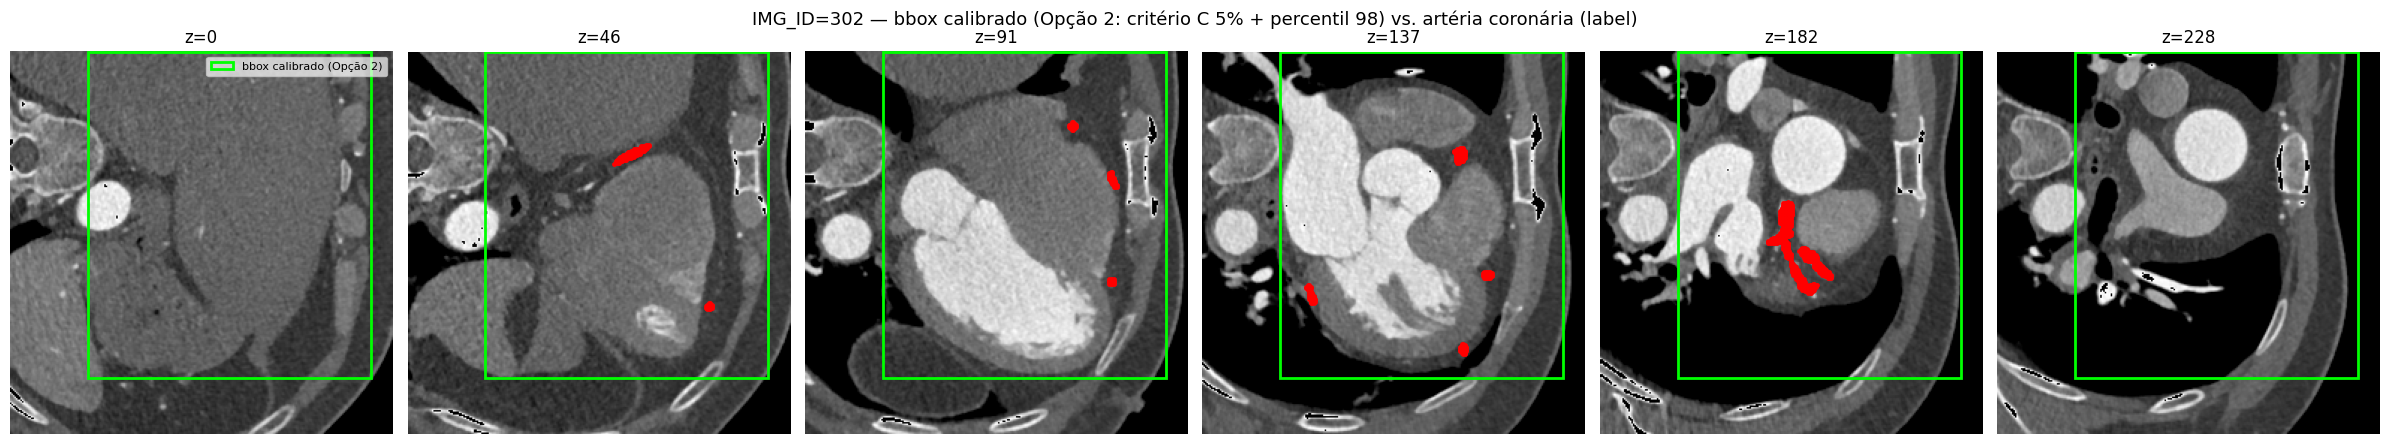

In [5]:
bbox_min = np.array([anchor_y + offset_min["y"], anchor_x + offset_min["x"], anchor_z + offset_min["z"]])
bbox_max = np.array([anchor_y + offset_max["y"], anchor_x + offset_max["x"], anchor_z + offset_max["z"]])
bbox_extent = bbox_max - bbox_min

print(f"bbox calibrado (min) y,x,z = {tuple(bbox_min.round(1))}")
print(f"bbox calibrado (max) y,x,z = {tuple(bbox_max.round(1))}")
print(f"bbox extent (y, x, z)      = {tuple(bbox_extent.round(1))} voxels (resolução reduzida)")

z_lo = max(0, int(np.floor(bbox_min[2])))
z_hi = min(lcc_image.shape[2] - 1, int(np.ceil(bbox_max[2])))
sample_z = sorted(set(np.linspace(z_lo, z_hi, 6).round().astype(int).tolist()))

fig, axes = plt.subplots(1, len(sample_z), figsize=(4 * len(sample_z), 4.5))
if len(sample_z) == 1:
    axes = [axes]
for i, (ax, z) in enumerate(zip(axes, sample_z)):
    ax.imshow(lcc_image[:, :, z], cmap="gray")

    label_slice = label_artery[:, :, z]
    if label_slice.any():
        ys, xs = np.nonzero(label_slice)
        ax.scatter(xs, ys, s=6, c="red", label="artéria (label)" if i == 0 else None)

    rect = plt.Rectangle(
        (bbox_min[1], bbox_min[0]),
        bbox_extent[1],
        bbox_extent[0],
        fill=False,
        edgecolor="lime",
        linewidth=2,
        label="bbox calibrado (Opção 2)" if i == 0 else None,
    )
    ax.add_patch(rect)
    ax.set_title(f"z={z}")
    ax.axis("off")

axes[0].legend(loc="upper right", fontsize=8, framealpha=0.7)
plt.suptitle(
    f"IMG_ID={IMG_ID} — bbox calibrado (Opção 2: critério C 5% + percentil 98) vs. artéria coronária (label)",
    fontsize=13,
)
plt.tight_layout()
plt.show()


## 4. Verificação — todos os voxels do label estão dentro do bbox calibrado?

Checagem voxel a voxel, igual à célula equivalente de `check_aorta_anchor.ipynb` — mas aqui o
resultado **não** é garantido por construção (o bbox não veio do label desta imagem, veio da
calibração sobre os 944 casos filtrados). Já confirmado independentemente antes de escrever este
notebook (perda real = 0% para IMG_ID=302); esta célula reproduz a checagem dentro do próprio
notebook, sem depender daquela verificação externa.

In [6]:
label_coords = np.argwhere(label_artery)
within_y = (label_coords[:, 0] >= bbox_min[0]) & (label_coords[:, 0] <= bbox_max[0])
within_x = (label_coords[:, 1] >= bbox_min[1]) & (label_coords[:, 1] <= bbox_max[1])
within_z = (label_coords[:, 2] >= bbox_min[2]) & (label_coords[:, 2] <= bbox_max[2])
covered = within_y & within_x & within_z

num_total = len(label_coords)
num_covered = int(covered.sum())
print(
    f"Voxels de artéria coronária dentro do bbox calibrado: {num_covered}/{num_total} "
    f"({num_covered / num_total:.2%})"
)

if num_covered != num_total:
    missing = label_coords[~covered]
    raise AssertionError(
        f"{num_total - num_covered} voxels de artéria FORA do bbox calibrado -- a Opção 2 não "
        f"garantiria perda zero para este caso. Primeiros fora: {missing[:5]}"
    )

print("Cobertura 100% confirmada -- sem perda de informação das artérias para IMG_ID=302 (Opção 2).")


Voxels de artéria coronária dentro do bbox calibrado: 23105/23105 (100.00%)
Cobertura 100% confirmada -- sem perda de informação das artérias para IMG_ID=302 (Opção 2).


## 5. Volume da imagem original vs. volume do bbox (cm³)

Mesmo cálculo de `Rv` da célula equivalente em `check_aorta_anchor.ipynb`
(`V = extensão_em_voxels × espaçamento_físico`), mas com o `bbox_extent` **calibrado** (célula 3)
em vez do bbox aproximado por label — este é o `Rv` real da Opção 2 para este caso, não uma
estimativa otimista.

In [7]:
V_bbox_mm3 = float(np.prod(bbox_extent) * np.prod(scaled_spacing))

nii_img, _ = load_raw_img_and_label(str(base_path / f"{IMG_ID}.img.nii.gz"))
V_original_mm3 = float(np.prod(nii_img.shape) * np.prod(image_data["spacing"]))

Rv_caso = 1.0 - (V_bbox_mm3 / V_original_mm3)

print(f"Shape original (resolução integral): {nii_img.shape}")
print(f"Spacing original (mm): {tuple(round(s, 4) for s in image_data['spacing'])}")
print()
print(f"Volume da imagem original: {V_original_mm3 / 1000:,.1f} cm³")
print(f"Volume do bbox calibrado (Opção 2): {V_bbox_mm3 / 1000:,.1f} cm³")
print(f"Rv (redução volumétrica) para este caso: {Rv_caso:.2%}")
print(f"(Rv médio documentado da Opção 2, sobre os 848 casos com perda zero: 36,26% -- "
      f"este caso individual pode divergir da média.)")


Shape original (resolução integral): (512, 512, 229)
Spacing original (mm): (np.float32(0.3438), np.float32(0.3438), np.float32(0.5))

Volume da imagem original: 3,546.8 cm³
Volume do bbox calibrado (Opção 2): 2,514.4 cm³
Rv (redução volumétrica) para este caso: 29.11%
(Rv médio documentado da Opção 2, sobre os 848 casos com perda zero: 36,26% -- este caso individual pode divergir da média.)


## 6. Resumo

| item | valor |
|---|---|
| IMG_ID | 302 |
| Critério de exclusão | C (`aorta_voxels`), `exclusion_pct=5%`, população inteira (994 casos) |
| Tamanho do bbox | `offset_percentile=98%` sobre os 944 casos filtrados |
| Cobertura do label (voxel a voxel) | 100% (verificado na célula 4) |
| Volume original | ver célula 5 |
| Volume do bbox | ver célula 5 |
| `Rv` deste caso | ver célula 5 |

Notebook de teste — não escreve nenhum artefato de produção, só visualiza e confere a calibração
já registrada em `docs/STATUS.md`/`docs/step6v2_aorta_anchor.md` para a Opção 2, na imagem
IMG_ID=302.